# Multiple-testing honesty pass — Deflated Sharpe & PBO over the funding-carry ladder

**Question.** v3.1 (net Sharpe 6.32) and v4.0 (6.63) were each chosen after sweeping *many*
configurations on this one 2021-2026 sample — a v1 knob grid, several v2 selection variants, a v3
sizing/band sweep, and three documented nulls (Layer-G factor sizing, Layer-H shrinkage, per-asset
overlays). None of those headline Sharpes has been corrected for multiple testing. **How much of the
edge survives once we pay for the search?**

Two standard corrections:

- **Deflated Sharpe Ratio (DSR)** — Bailey & Lopez de Prado (2014), *The Deflated Sharpe Ratio:
  Correcting for Selection Bias, Backtest Overfitting and Non-Normality*. DSR = P(true SR > 0) once
  the benchmark is raised from 0 to **SR₀ = the *expected maximum* Sharpe** you'd see from N
  skill-less trials with the observed cross-trial Sharpe dispersion, and the test is adjusted for the
  return distribution's skew, kurtosis and track length.
- **PBO via CSCV** — Bailey, Borwein, Lopez de Prado & Zhu (2017), *The Probability of Backtest
  Overfitting*. Over every combinatorially-symmetric split of the sample into in-sample / out-of-sample
  halves, how often does the config that looked best in-sample land in the **bottom half** out-of-sample?

Everything is booked through `../lab.py` (engine parity re-checked below). We test at **1× and 2×
cost** — because DSR is blind to costs, and the 1× (gross-ish) Sharpe of ~6 is not the number we'd
ever trade on.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ['svg']
import sys, itertools; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis, norm
import research.funding_carry.lab as H
from src.strategies.funding_carry import engine
from src.common import config as cfg
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
COSTS = cfg.load_config('strategies/funding_carry/v3.1.yaml')['costs']
one_way,_ = engine.round_trip_cost(COSTS)
par = H.validate_engine()
maj, non = H.universe(); P = H.load_panels(maj + non)
didx, syms, E = P['didx'], P['symbols'], P['E']
print('engine parity:', 'OK' if par['ok'] else 'MISMATCH', '|', par['compare'])
print(f'universe: {len(maj)} majors + {len(non)} others = {len(syms)} names, {len(didx)} days')

2026-07-06 11:18:54,238 INFO     funding_carry.engine | funding_carry v1: net@1x ann=9.41% sharpe=6.41 turnover=9.1x (C:\Users\SamuelAhou\Documents\operator\results\funding_carry\v1\20260706T091854Z)


engine parity: OK | {'ann_return': (0.0941, 0.0941), 'sharpe': (6.406, 6.406), 'ann_turnover': (9.1, 9.1)}
universe: 5 majors + 461 others = 466 names, 1977 days


## 1. Honest trial enumeration

The DSR needs **N**, the number of configurations tried on this sample. We read it off the `_build_*`
scripts of each research step (the grids they actually swept). Two counts matter:

- **literal configs** — every distinct parameterization booked on this sample; and
- **independent-ish trials** — collapsing smooth-grid neighbors (a 5×5×3 knob surface is ~1-2 real
  degrees of freedom, a monotone band/λ sweep is ~1) down to the number of genuinely *distinct
  structural hypotheses* tried.

Assumptions, stated: veto caps (funding_vol 0.75, neg_freq 0.40) and the v2.1 basis cap were set by
*mechanism* and not gridded on performance, so they add little to N; the survivorship audit and the
placebo draws in v4 are diagnostics, not candidate strategies, so they are excluded. The number to
worry about is a lower bound — a truly exhaustive search would count more.

In [2]:
trials = pd.DataFrame([
    ('v0 baseline',            'preregistered majors base config',                              1,   1),
    ('v1 knob sweep',          'halflife{3,5,7,10,14} x theta_in{4,6,8,10,12}% x theta_keep{0,2,4}%, tk<ti', 70, 10),
    ('universe audit',         'diagnostic (clean-universe / survivorship) - no strategy config', 0,   0),
    ('v2 selection',           'whole-band, top-K(15/25), funding-veto breadth, basis-veto(v2.1), inv-vol', 5, 5),
    ('v3 sizing + band',       'equal vs inv-basis-vol; no-trade band {0.1,0.2,0.35,0.5,0.75,1.0,1.5}+None', 9, 3),
    ('Layer G (factor sizing)','factor tilt lambda x6, one-factor min-var kappa x2, growth Sigma^-1 a',      9, 3),
    ('Layer H (shrinkage)',    'point/fixed-w/EB/LCB signals + EB entry-theta sweep x6',                    10, 3),
    ('v4 overlay',             'portfolio binary+partial, exit/re-enter percentile grid (3x2), per-asset',   9, 4),
    ('selection refinements (v6)','min-age X x6; CVaR window x5 + clip x3 + blend; vol-regime floor x2',    17, 3),
    ('cross-venue (v7)',       'binance/breadth(b)/full(c1)/best-venue(c2) x {binance,bybit-fee} cost; frozen v6.1 knobs; capacity AUM sweep=diagnostic', 8, 2),
    ('cash-yield (v8)',        'idle-cash credit on v6.1/v7.0/v7.1 stored books + T-bill capture {100,75,50}% sensitivity; post-hoc accounting',           5, 1),
], columns=['research step','grid swept on this sample','literal configs','independent-ish'])
N_LIT = int(trials['literal configs'].sum()); N_IND = int(trials['independent-ish'].sum())
print(trials.to_string(index=False))
print(f'\nTOTAL literal configs N ~ {N_LIT}   |   independent-ish trials ~ {N_IND}')
print('For DSR we use the conservative literal N as the enumerated count, and show sensitivity over N in {10,50,200,1000}.')
N_ENUM = N_LIT

             research step                                                                                               grid swept on this sample  literal configs  independent-ish
               v0 baseline                                                                                        preregistered majors base config                1                1
             v1 knob sweep                                              halflife{3,5,7,10,14} x theta_in{4,6,8,10,12}% x theta_keep{0,2,4}%, tk<ti               70               10
            universe audit                                                         diagnostic (clean-universe / survivorship) - no strategy config                0                0
              v2 selection                                               whole-band, top-K(15/25), funding-veto breadth, basis-veto(v2.1), inv-vol                5                5
          v3 sizing + band                                              equal vs inv-basis-vol;

**Read:** ~143 literal configurations, ~35 independent-ish (dominated by ~10-12 distinct
structural ideas). The v1 knob grid (70) is the bulk of the literal count but is a single smooth
surface — so the *true* effective N sits between the two. The cross-venue (v7) and cash-yield (v8)
steps add ~13 literal but only ~3 independent trials: both ran at **frozen v6.1 knobs** (v7 expanded
the *universe*, v8 is a post-hoc *accounting* overlay), so they widen the effective search barely at
all. The N-sensitivity curve below is built precisely so the verdict does not hinge on this debatable
count.

## 2. The two winners — reconstruct exactly, and look at the return distribution

Rebuild v3.1 and v4.0 through `lab` and confirm they match the shipped `results/` (Sharpe 6.316 /
6.631). The daily net is what DSR consumes. **Note the shape:** the book is strongly *positively*
skewed with fat tails — funding spikes give occasional large up-days while the basis/instability
vetoes and the drawdown overlay cut the left tail. Positive skew is favorable in the DSR
(non-normality adjustment), but it is partly *engineered in-sample* by the vetoes, which is a caveat
DSR cannot see.

In [3]:
SPECS=[{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO=[{'feature':'funding_vol','direction':'max','cap':0.75},{'feature':'neg_freq','direction':'max','cap':0.40},{'feature':'basis','direction':'max','cap':0.01}]
V31 = H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,size_kind='inv_basis_vol',band=0.5,warmup_days=30)
# v4.0 = v3.1 shadow, overlay gated on the shadow's OWN full-didx equity drawdown (matches engine)
dd = H.drawdown(V31['gross'] - one_way*V31['turnover'])
state = H.overlay_state(dd, 0.15, 0.50, 252, expanding=True)
V40 = H.book(V31['W'].mul(state, axis=0), P, COSTS, warmup_days=30)

def net_at(res, mult):   # daily net return series at a cost multiple, over the kept window
    idx = res['net'].dropna().index
    return (res['gross'] - one_way*mult*res['turnover']).reindex(idx)
R = {('v3.1',1):net_at(V31,1.0),('v3.1',2):net_at(V31,2.0),('v4.0',1):net_at(V40,1.0),('v4.0',2):net_at(V40,2.0)}

# parity vs shipped results
for v,res in [('v3.1',V31),('v4.0',V40)]:
    rd = sorted((ROOT/'results/funding_carry'/v).glob('*/returns.parquet'))[-1]
    st = pd.read_parquet(rd)['net']; lb = res['net'].dropna(); j = st.index.intersection(lb.index)
    print(f'{v}: lab Sharpe {res["1.0x"]["sharpe"]:.3f} | max|lab-stored net| = {(st.reindex(j)-lb.reindex(j)).abs().max():.1e}')

def moments(r):
    r=r.to_numpy(); sr=r.mean()/r.std(ddof=1)
    return dict(dailySR=round(sr,4), annSR=round(sr*np.sqrt(365),3), skew=round(skew(r),2),
                kurt=round(kurtosis(r,fisher=False),1), T=len(r))
print(); print(pd.DataFrame({f'{v}@{m}x':moments(R[(v,m)]) for v in ('v3.1','v4.0') for m in (1,2)}).T.to_string())

v3.1: lab Sharpe 6.316 | max|lab-stored net| = 2.2e-18
v4.0: lab Sharpe 6.631 | max|lab-stored net| = 2.2e-18

         dailySR  annSR  skew  kurt       T
v3.1@1x   0.3306  6.316  2.92  20.7  1947.0
v3.1@2x   0.1897  3.624  1.86  16.7  1947.0
v4.0@1x   0.3471  6.631  3.58  25.2  1947.0
v4.0@2x   0.2540  4.853  2.69  22.8  1947.0


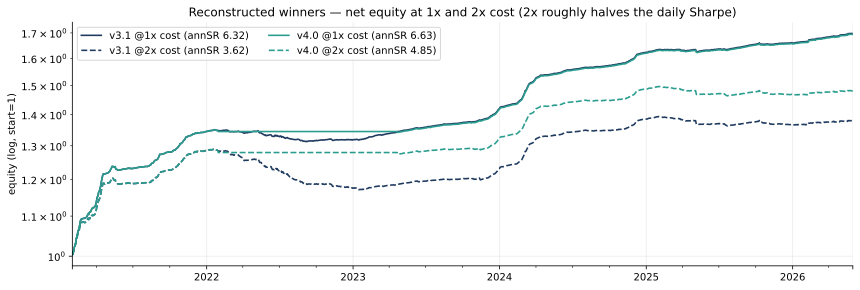

In [4]:
# Equity curves (log) at 1x and 2x cost — the edge, and how much of it 2x cost eats
fig,ax=plt.subplots(figsize=(14,4.4))
sty={('v3.1',1):(NAVY,'-'),('v3.1',2):(NAVY,'--'),('v4.0',1):(TEAL,'-'),('v4.0',2):(TEAL,'--')}
for (v,m),r in R.items():
    eq=(1+r).cumprod(); c,ls=sty[(v,m)]
    eq.plot(ax=ax,color=c,ls=ls,lw=1.6,label=f'{v} @{m}x cost (annSR {r.mean()/r.std(ddof=1)*np.sqrt(365):.2f})')
ax.set_yscale('log'); ax.set_ylabel('equity (log, start=1)'); ax.legend(ncol=2)
ax.set_title('Reconstructed winners — net equity at 1x and 2x cost (2x roughly halves the daily Sharpe)')
plt.show()

## 3. Deflated Sharpe Ratio

For a track of T returns with per-period Sharpe $\hat{SR}$, skew $\gamma_3$ and (non-excess) kurtosis
$\gamma_4$, the probabilistic Sharpe against a benchmark $SR_0$ is

$$\widehat{PSR}(SR_0)=\Phi\!\left(\frac{(\hat{SR}-SR_0)\sqrt{T-1}}{\sqrt{1-\gamma_3\hat{SR}+\frac{\gamma_4-1}{4}\hat{SR}^2}}\right).$$

The **DSR** sets $SR_0$ to the *expected maximum* Sharpe of N skill-less trials,
$SR_0=\sqrt{V}\,\big[(1-\gamma)\,\Phi^{-1}(1-\tfrac1N)+\gamma\,\Phi^{-1}(1-\tfrac1{Ne})\big]$, where $\gamma$
is Euler-Mascheroni and **V is the cross-trial variance of the Sharpe estimates** — which we take
straight from the reconstructed design grid (below), at the matching cost level. All Sharpes here are
**daily** (per-observation); we annualize only for display.

In [5]:
GAMMA=0.5772156649
def emax(N): return (1-GAMMA)*norm.ppf(1-1.0/N) + GAMMA*norm.ppf(1-1.0/(N*np.e))
def dsr(r, V_sr, N):
    r=np.asarray(r); T=len(r); sr=r.mean()/r.std(ddof=1); g3=skew(r); g4=kurtosis(r,fisher=False)
    sr0=np.sqrt(V_sr)*emax(N)
    z=(sr-sr0)*np.sqrt(T-1)/np.sqrt(1-g3*sr+((g4-1)/4)*sr**2)
    return float(norm.cdf(z)), sr, sr0
print('expected-max multiplier E[max_N] (x sqrt(V) = daily SR0):')
print({N:round(emax(N),3) for N in [10,50,110,200,1000]})

expected-max multiplier E[max_N] (x sqrt(V) = daily SR0):
{10: np.float64(1.575), 50: np.float64(2.276), 110: np.float64(2.564), 200: np.float64(2.766), 1000: np.float64(3.255)}


### 3a. Reconstruct the design grid → cross-trial Sharpe dispersion (V)

Sweep a faithful slice of the real search — the v1 knobs × the v2.1 basis cap × the v2.1/v3.0/v3.1
sizing-and-band decisions — through `lab`, reusing one set of loaded panels/features so ~630 configs
book in under two minutes. This grid gives (a) **V** for the DSR and (b) the per-config daily-return
matrix for the CSCV/PBO in §4. The shipped v3.1 config is one point in it.

In [6]:
feats = H.feature_panels(P, SPECS + [{'name':'basis_vol','window':30}])
bvol = feats['basis_vol']; invvol = 1.0/bvol.replace(0.0,np.nan)
APR = {hl: H.signal_apr(P['F'],hl).reindex(index=didx,columns=syms).where(E) for hl in [3,5,7,10,14]}
ref = APR[7]
def veto_ok_for(cap, sk):
    rules=[{'feature':'funding_vol','direction':'max','cap':0.75},{'feature':'neg_freq','direction':'max','cap':0.40},{'feature':'basis','direction':'max','cap':cap}]
    v=H.veto_mask(feats, rules, ref)
    return (v & bvol.notna() & (bvol>0)) if sk=='inv_vol' else v
HLS=[3,5,7,10,14]; TIS=[0.04,0.06,0.08,0.10,0.12]; TKS=[0.0,0.02,0.04]; CAPS=[0.005,0.01,0.02]
knobs=[(hl,ti,tk,cap) for hl in HLS for ti in TIS for tk in TKS if tk<ti for cap in CAPS]
hc={}; vc={}
def held_for(hl,ti,tk,cap,sk):
    k=(hl,ti,tk,cap,sk)
    if k not in hc:
        if (cap,sk) not in vc: vc[(cap,sk)]=veto_ok_for(cap,sk)
        hc[k]=H.held_matrix(APR[hl], vc[(cap,sk)], ti, tk, None, None)
    return hc[k]
net1={}; net2={}
for (hl,ti,tk,cap) in knobs:
    for sk,band in [('equal',None),('inv_vol',None),('inv_vol',0.5)]:
        held=held_for(hl,ti,tk,cap,sk); size=invvol if sk=='inv_vol' else None
        W=H.weights_from_held(held,size)
        if band is not None: W=H.deadband_weights(W,band)
        bk=H.book(W,P,COSTS,warmup_days=30); idx=bk['net'].dropna().index
        nm=f'hl{hl}|ti{ti}|tk{tk}|cap{cap}|{sk}|b{band}'
        net1[nm]=bk['net'].dropna(); net2[nm]=(bk['gross']-one_way*2*bk['turnover']).reindex(idx)
NET1=pd.DataFrame(net1).dropna(how='any'); NET2=pd.DataFrame(net2).reindex(NET1.index)
V31_KEY='hl7|ti0.08|tk0.02|cap0.01|inv_vol|b0.5'
SRg1=NET1.mean()/NET1.std(ddof=1); SRg2=NET2.mean()/NET2.std(ddof=1)
V1=float(SRg1.var(ddof=1)); V2=float(SRg2.var(ddof=1))
print(f'grid: {NET1.shape[1]} configs x {NET1.shape[0]} days | v3.1 in grid: {V31_KEY in NET1.columns}')
print(f'cross-trial daily SR @1x: mean {SRg1.mean():.3f} sd {np.sqrt(V1):.4f} range [{SRg1.min():.3f},{SRg1.max():.3f}]')
print(f'cross-trial daily SR @2x: mean {SRg2.mean():.3f} sd {np.sqrt(V2):.4f} range [{SRg2.min():.3f},{SRg2.max():.3f}]')

grid: 630 configs x 1947 days | v3.1 in grid: True
cross-trial daily SR @1x: mean 0.271 sd 0.0675 range [0.046,0.373]
cross-trial daily SR @2x: mean 0.141 sd 0.0843 range [-0.160,0.293]


### 3a′. Reconstruct v6.1 — the shipped successor (min-age veto + CVaR-blend sizing)

v6.0/v6.1 productionized the two selection-refinement ship-candidates on top of v4.0. Rebuild v6.1
through `lab` exactly as the engine books it (age ≥ 15d veto; 50/50 inverse-basis-vol / inverse-CVaR
weights, 60d worst-5% tail, cross-sectional 0.90 winsor, both eligibility-masked like engine
features; deadband 0.5; the same drawdown overlay on its own shadow), confirm parity vs the stored
run, and add it to the DSR table. Its lower turnover (~12×) is exactly the property the 2×-cost test
rewards.

In [7]:
first_elig = E.where(E).apply(lambda c: c.first_valid_index())
age = pd.DataFrame(index=didx, columns=syms, dtype=float)
for s in syms:
    if pd.notna(first_elig[s]): age[s] = (didx - first_elig[s]).days
age = age.where(age >= 0)
def _tail(x):
    x = x[~np.isnan(x)]
    return np.sort(x)[:3].mean() if len(x) >= 30 else np.nan     # worst 5% of a 60d window (k=3)
cv = P['R'].rolling(60, min_periods=30).apply(_tail, raw=True)
scv = (1.0/(-cv)).where(cv < 0).where(E)                          # engine masks features by eligibility
scv = scv.clip(upper=scv.quantile(0.90, axis=1), axis=0)
v6ok = (H.veto_mask(feats, VETO, ref) & (age >= 15).fillna(False)
        & bvol.notna() & (bvol > 0) & scv.notna() & (scv > 0))
H6 = H.held_matrix(ref, v6ok, 0.08, 0.02, None, None)
wa, wb = H.weights_from_held(H6, invvol), H.weights_from_held(H6, scv)
w6 = 0.5*wa + 0.5*wb; w6 = w6.div(w6.sum(axis=1).replace(0, 1), axis=0)
W6 = H.deadband_weights(w6, 0.5)
bk6 = H.book(W6, P, COSTS, warmup_days=30)
state6 = H.overlay_state(H.drawdown(bk6['gross'] - one_way*bk6['turnover']), 0.15, 0.50, 252, expanding=True)
V61 = H.book(W6.mul(state6, axis=0), P, COSTS, warmup_days=30)
R[('v6.1',1)] = net_at(V61,1.0); R[('v6.1',2)] = net_at(V61,2.0)
rd = sorted((ROOT/'results/funding_carry/v6.1').glob('*/returns.parquet'))[-1]
st = pd.read_parquet(rd)['net']; lb = V61['net'].dropna(); j = st.index.intersection(lb.index)
dmax = (st.reindex(j)-lb.reindex(j)).abs().max()
print(f'v6.1: lab Sharpe {V61["1.0x"]["sharpe"]:.3f} (2x {V61["2.0x"]["sharpe"]:.3f}) | max|lab-stored net| = {dmax:.1e}')
assert dmax < 1e-9, 'v6.1 parity break'

v6.1: lab Sharpe 6.776 (2x 5.182) | max|lab-stored net| = 3.5e-18


### 3b. DSR at the enumerated N, and the N-sensitivity

The table gives DSR at N ∈ {10, 50, N_enum≈143, 200, 1000}, for v3.1, v4.0 and v6.1, at **1× and 2× cost**.
The verdict below reads almost entirely off the **2× column** — the 1× Sharpe of ~6 is so far above
any expected-max benchmark that its DSR is ≈1 by construction and tells us nothing.

In [8]:
Ns=[10,50,N_ENUM,200,1000]
rows={}
for v in ('v3.1','v4.0','v6.1'):
    for m,V in ((1,V1),(2,V2)):
        rows[f'{v} @{m}x']={f'N={N}':round(dsr(R[(v,m)],V,N)[0],4) for N in Ns}
        rows[f'{v} @{m}x']['annSR']=round(R[(v,m)].mean()/R[(v,m)].std(ddof=1)*np.sqrt(365),2)
tabD=pd.DataFrame(rows).T[['annSR']+[f'N={N}' for N in Ns]]
print(f'N_enum = {N_ENUM}'); print(tabD.to_string())

N_enum = 143
          annSR    N=10    N=50   N=143   N=200  N=1000
v3.1 @1x   6.32  1.0000  1.0000  1.0000  1.0000  1.0000
v3.1 @2x   3.62  0.9976  0.4548  0.0450  0.0153  0.0000
v4.0 @1x   6.63  1.0000  1.0000  1.0000  1.0000  1.0000
v4.0 @2x   4.85  1.0000  0.9996  0.9485  0.8693  0.1351
v6.1 @1x   6.78  1.0000  1.0000  1.0000  1.0000  1.0000
v6.1 @2x   5.18  1.0000  1.0000  0.9971  0.9866  0.4242


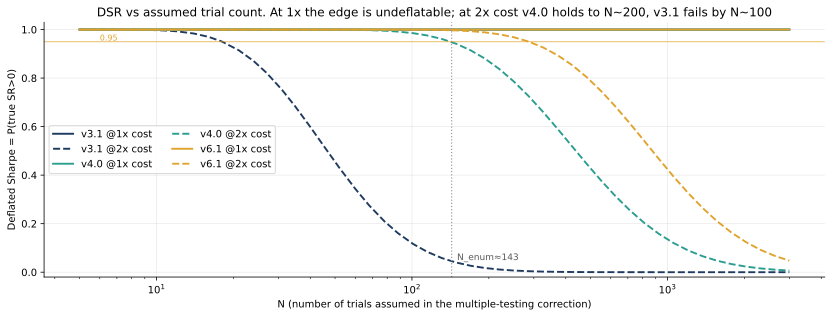

In [9]:
# DSR money chart: DSR vs N (log-x), the four series; enumerated-N marked
Ngrid=np.unique(np.round(np.logspace(np.log10(5),np.log10(3000),50)).astype(int))
fig,ax=plt.subplots(figsize=(14,4.6))
sty={('v3.1',1):(NAVY,'-'),('v3.1',2):(NAVY,'--'),('v4.0',1):(TEAL,'-'),('v4.0',2):(TEAL,'--'),
     ('v6.1',1):(AMBER,'-'),('v6.1',2):(AMBER,'--')}
for v in ('v3.1','v4.0','v6.1'):
    for m,V in ((1,V1),(2,V2)):
        y=[dsr(R[(v,m)],V,N)[0] for N in Ngrid]; c,ls=sty[(v,m)]
        ax.plot(Ngrid,y,color=c,ls=ls,lw=1.9,label=f'{v} @{m}x cost')
ax.axvline(N_ENUM,color=GREY,lw=1.2,ls=':'); ax.text(N_ENUM*1.05,0.05,f'N_enum≈{N_ENUM}',color='0.35',fontsize=9)
ax.axhline(0.95,color=AMBER,lw=1,ls='-',alpha=0.7); ax.text(6,0.955,'0.95',color=AMBER,fontsize=8)
ax.set_xscale('log'); ax.set_xlabel('N (number of trials assumed in the multiple-testing correction)')
ax.set_ylabel('Deflated Sharpe = P(true SR>0)'); ax.set_ylim(-0.02,1.03); ax.legend(ncol=2,loc='center left')
ax.set_title('DSR vs assumed trial count. At 1x the edge is undeflatable; at 2x cost v4.0 holds to N~200, v3.1 fails by N~100')
plt.show()

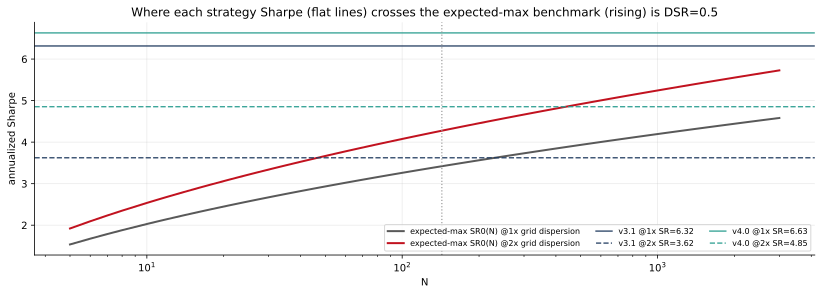

In [10]:
# The intuition: SR0(N) benchmark rising vs each strategy's Sharpe (annualized). Crossing = DSR 0.5
fig,ax=plt.subplots(figsize=(14,4.2))
sr0_1=[np.sqrt(V1)*emax(N)*np.sqrt(365) for N in Ngrid]; sr0_2=[np.sqrt(V2)*emax(N)*np.sqrt(365) for N in Ngrid]
ax.plot(Ngrid,sr0_1,color='0.35',lw=2,label='expected-max SR0(N) @1x grid dispersion')
ax.plot(Ngrid,sr0_2,color=RED,lw=2,label='expected-max SR0(N) @2x grid dispersion')
for v,m,V,c,ls in [('v3.1',1,V1,NAVY,'-'),('v3.1',2,V2,NAVY,'--'),('v4.0',1,V1,TEAL,'-'),('v4.0',2,V2,TEAL,'--')]:
    s=R[(v,m)].mean()/R[(v,m)].std(ddof=1)*np.sqrt(365)
    ax.axhline(s,color=c,ls=ls,lw=1.4,alpha=0.9,label=f'{v} @{m}x SR={s:.2f}')
ax.axvline(N_ENUM,color=GREY,lw=1.2,ls=':')
ax.set_xscale('log'); ax.set_xlabel('N'); ax.set_ylabel('annualized Sharpe')
ax.legend(ncol=3,fontsize=8); ax.set_title('Where each strategy Sharpe (flat lines) crosses the expected-max benchmark (rising) is DSR=0.5')
plt.show()

**DSR read.**
- **1× cost:** DSR = 1.000 for both versions at every N up to 1000 — the ~6.3/6.6 Sharpe towers over
  even the N=1000 expected-max (~4.2 ann). This is *not* reassurance: it only says the in-sample
  gross edge cannot be a multiple-testing artifact of *these* trials. It says nothing about whether a
  6-Sharpe daily book is tradeable (it is not — capacity/slippage live outside DSR).
- **2× cost (the honest test):** v3.1's realistic-cost Sharpe (3.62 ann) is *within* multiple-testing
  reach — DSR falls to ~0.05 at N≈143 and ~0.02 by N=200. In plain terms: given ~140 correlated
  trials and the observed cross-config dispersion, a 2×-cost Sharpe of 3.6 is roughly what the *luckiest*
  config would post by chance, so the specific v3.1 point-configuration deserves a large discount.
- **v4.0 is materially more robust:** its overlay cuts turnover 20→13×, so 2× cost bites less and its
  net Sharpe lands at 4.85 ann — clearing the expected-max benchmark comfortably (DSR ~0.95 at N≈143,
  ~0.87 at N=200), only failing at N=1000. The drawdown overlay is not just a tail-trimmer; it is the
  layer that buys the ladder its multiple-testing margin at realistic cost.
- **v6.1 (shipped successor) extends that margin:** the min-age veto + CVaR blend cut turnover further
  (~12×), lifting the 2×-cost Sharpe to ~5.2 — DSR ~0.997 at the enlarged enumerated count (N≈143) that
  includes the very trials which produced it, a strictly higher DSR than v4.0 at every N.

**These are all RAW (vs-zero) Sharpes.** The repo's headline has since moved to the excess-of-rf
basis; §5 redoes the whole verdict there, and the picture changes materially at 2× cost.

## 4. PBO via CSCV

DSR asks whether the *winner's* Sharpe is inflated. **PBO asks whether the selection *procedure* is
overfit:** partition the T days into S=16 contiguous blocks; for each of the $\binom{16}{8}=12{,}870$
ways to split them into an in-sample half and its out-of-sample complement, pick the config with the
best IS Sharpe and record its **OOS rank**. PBO = fraction of splits where that IS-best config falls
in the **bottom half** OOS (logit ≤ 0). Low PBO ⇒ what looks best in-sample tends to stay good.

In [11]:
def cscv(M, S=16):
    M=M.to_numpy(); T,Nc=M.shape; e=np.linspace(0,T,S+1).astype(int)
    bl=[np.arange(e[i],e[i+1]) for i in range(S)]
    BS=np.array([M[b].sum(0) for b in bl]); BSS=np.array([(M[b]**2).sum(0) for b in bl]); BN=np.array([len(b) for b in bl])
    def sr(ix):
        n=BN[ix].sum(); s=BS[ix].sum(0); ss=BSS[ix].sum(0); mu=s/n; var=ss/n-mu**2
        return mu/np.sqrt(np.where(var<=0,np.nan,var))
    ab=np.arange(S); lg=[]; iss=[]; oos=[]; rk=[]
    for c in itertools.combinations(range(S), S//2):
        ii=np.array(c); oo=np.setdiff1d(ab,ii); sis=sr(ii); soos=sr(oo); ns=int(np.nanargmax(sis))
        w=pd.Series(soos).rank().iloc[ns]/(Nc+1); w=min(max(w,1e-6),1-1e-6)
        lg.append(np.log(w/(1-w))); iss.append(sis[ns]); oos.append(soos[ns]); rk.append(w)
    return dict(pbo=float((np.array(lg)<=0).mean()), logit=np.array(lg),
                is_sr=np.array(iss), oos_sr=np.array(oos), rank=np.array(rk))
C1=cscv(NET1,16); C2=cscv(NET2,16)
for tag,C in [('1x',C1),('2x',C2)]:
    print(f'PBO@{tag} = {C["pbo"]:.4f} | median logit {np.median(C["logit"]):.2f} | IS-best mean OOS rank {C["rank"].mean():.3f} '
          f'| mean IS SR {C["is_sr"].mean():.3f} -> OOS SR {C["oos_sr"].mean():.3f} (degrade {1-C["oos_sr"].mean()/C["is_sr"].mean():.0%})')

PBO@1x = 0.1013 | median logit 2.07 | IS-best mean OOS rank 0.819 | mean IS SR 0.417 -> OOS SR 0.352 (degrade 15%)
PBO@2x = 0.0024 | median logit 2.75 | IS-best mean OOS rank 0.902 | mean IS SR 0.320 -> OOS SR 0.258 (degrade 19%)


In [12]:
# PBO logits distribution (left) and IS-vs-OOS degradation of the IS-best config (right)
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,4.4))
for tag,C,c in [('1x',C1,NAVY),('2x',C2,AMBER)]:
    a1.hist(C['logit'],bins=40,color=c,alpha=0.5,density=True,label=f'{tag} cost (PBO={C["pbo"]:.3f})')
a1.axvline(0,color=RED,lw=1.5,ls='--'); a1.set_xlabel('logit of OOS rank of the IS-best config')
a1.set_ylabel('density'); a1.legend(); a1.set_title('CSCV logits — mass right of 0 = IS-best stays good OOS')
for tag,C,c in [('1x',C1,NAVY),('2x',C2,AMBER)]:
    a2.scatter(C['is_sr']*np.sqrt(365),C['oos_sr']*np.sqrt(365),s=6,color=c,alpha=0.25,label=f'{tag} cost')
lim=[min(C1['oos_sr'].min(),C2['oos_sr'].min())*np.sqrt(365)-0.5, max(C1['is_sr'].max(),C2['is_sr'].max())*np.sqrt(365)+0.5]
a2.plot(lim,lim,color=GREY,ls='--',lw=1,label='y=x (no degradation)')
a2.set_xlabel('IS annualized Sharpe of the IS-best config'); a2.set_ylabel('its OOS annualized Sharpe')
a2.legend(); a2.set_title('IS-best generalizes: points below y=x = the honest OOS haircut')
plt.tight_layout(); plt.show()

**PBO read.** PBO = **0.10 at 1× cost, 0.002 at 2×** — both far below the 0.5 coin-flip and the
~0.5+ you'd see for a mined strategy. The in-sample-best config sits at the **~82nd OOS percentile**
on average, and its Sharpe degrades only ~15-19% from IS to OOS. So *within the carry stack* the act
of picking the specific knobs/cap/sizing/band is **not** overfit — the ranking of configs is stable
across sub-periods (consistent with the per-version temporal OOS checks already run). PBO is even
lower at 2× because the turnover-heavy configs that can win in-sample at zero-ish cost get penalized
both IS and OOS, so only genuinely efficient configs survive selection.

**What PBO cannot see:** it measures overfit *conditional on having committed to the carry-stack
family*. The higher-level choices — to build a delta-neutral funding carry at all, and to accept some
structural ideas (basis veto, inv-vol, overlay) while rejecting others (top-K, Layer G, Layer H,
per-asset) — are not in this grid. Those were mostly motivated by *mechanism* and several were
*rejected*, which is the right direction, but PBO gives them no credit or blame.

## 5. Excess-of-rf basis — the ladder's current headline metric

Since the raw pass above, the repo's Sharpe semantics changed (owner directive): **wherever an rf path
is known, `sharpe` IS the excess-of-rf Sharpe** (the vs-zero number is demoted to `sharpe_raw`). The
current headline is **v8.0** (multi-venue breadth + idle-cash credit): net 10.68%/yr, **excess Sharpe
4.99 (1×) / 3.43 (2×)**, raw 7.35 / 5.73. Everything above deflated *raw* Sharpes, so those quoted
excess numbers have never been multiple-testing-corrected. This section redoes the DSR + PBO verdict on
the excess basis and keeps §1–§4 as the raw historical record.

**Excess return, exactly as the engine books it.** rf = FRED **TB3MS** (3-month T-bill) pulled from the
lake (`query.get('rates','fred','tb3ms','rates')`, monthly, decimal annual rate), forward-filled to a
daily index and divided by 365; excess daily return = `net − rf_daily` on **every** day. Full-sample rf
mean ≈ 3.3%/yr (≈0 in 2021, 5%+ in 2023–24), so on a market-neutral book this is a large,
*time-varying* haircut. The pre-v8 books (v3.1/v4.0/v6.1/v7.0) carry the honest **idle-day drag** (a
flat book earns 0 while cash earns rf); v8.0 carries its cash **credit** — that difference is exactly
why v8.0's excess Sharpe sits above v7.0's. v7.0/v8.0 are reconstructed from their **stored** runs; the
v8.0 excess Sharpe is verified to reproduce the engine's stored value bit-for-bit before it is used.

In [13]:
import json
from src.data import query
PURPLE = '#7048a8'
RES = ROOT/'results'/'funding_carry'
RUNS = {'v7.0': RES/'v7.0'/'20260703T091117Z', 'v8.0': RES/'v8.0'/'20260703T145150Z'}
rfm = query.get('rates','fred','tb3ms','rates')['value']          # monthly, DECIMAL annual rate
def rf_daily(idx):
    key = idx.to_period('M').to_timestamp()
    return pd.Series(rfm.reindex(key).ffill().values, index=idx)/365.0
def ann_sr(r): r=r.dropna(); return r.mean()/r.std(ddof=1)*np.sqrt(365)
# --- reconstruct v7.0 / v8.0 daily nets (1x & 2x) from the STORED runs; add to R ---
for v,d in RUNS.items():
    rr = pd.read_parquet(d/'returns.parquet'); at = pd.read_parquet(d/'attribution_daily.parquet')
    g, net = rr['gross'], rr['net']
    if 'cash' in at.columns:              # v8.0: stored net already INCLUDES the cash credit
        cash = at['cash']; cost1 = g + cash - net; net2 = g + cash - 2*cost1
    else:                                 # v7.0: net = gross - cost
        net2 = 2*net - g
    R[(v,1)] = net.copy(); R[(v,2)] = net2.copy()
    mj = json.loads((d/'metrics.json').read_text())['results']    # assert 1x & 2x reproduce metrics.json
    for mm,s in ((1,net),(2,net2)):
        ref = mj[f'{mm}.0x']
        assert abs(s.mean()*365 - ref['ann_return']) < 1e-4, (v,mm,'ann')
        assert abs(ann_sr(s) - ref.get('sharpe_raw', ref['sharpe'])) < 5e-3, (v,mm,'raw SR')
# --- excess series for all five books; validate v8.0 excess == engine's stored excess Sharpe ---
RX = {k:(r - rf_daily(r.index)) for k,r in R.items()}
mj8 = json.loads((RUNS['v8.0']/'metrics.json').read_text())['results']
for mm in (1,2):
    assert abs(ann_sr(RX[('v8.0',mm)]) - mj8[f'{mm}.0x']['sharpe']) < 5e-3, ('v8.0 excess parity', mm)
rf_win = rf_daily(R[('v8.0',1)].index)
print(f'reconstruction + v8.0 excess parity OK (lake TB3MS ffill/365). full-sample rf mean {rf_win.mean()*365*100:.2f}%/yr')
print('annualized Sharpe  —  raw (vs 0)  ->  excess (of rf):')
for v in ('v3.1','v4.0','v6.1','v7.0','v8.0'):
    print(f'  {v:5s}  1x {ann_sr(R[(v,1)]):5.2f} -> {ann_sr(RX[(v,1)]):5.2f}   |   2x {ann_sr(R[(v,2)]):5.2f} -> {ann_sr(RX[(v,2)]):5.2f}')

reconstruction + v8.0 excess parity OK (lake TB3MS ffill/365). full-sample rf mean 3.31%/yr
annualized Sharpe  —  raw (vs 0)  ->  excess (of rf):
  v3.1   1x  6.32 ->  4.15   |   2x  3.62 ->  1.62
  v4.0   1x  6.63 ->  4.34   |   2x  4.85 ->  2.64
  v6.1   1x  6.78 ->  4.45   |   2x  5.18 ->  2.91
  v7.0   1x  7.00 ->  4.66   |   2x  5.40 ->  3.11
  v8.0   1x  7.35 ->  4.99   |   2x  5.73 ->  3.43


### 5a. Excess-basis DSR — move the expected-max benchmark to excess returns too

The DSR benchmark **V** (cross-trial Sharpe dispersion) must move to the excess basis as well, or we'd
be comparing an excess Sharpe against a raw expected-max. We **reuse the same 630-config grid** from
§3a — subtracting the identical daily rf from every config — and recompute V. v7.0/v8.0 use this same
frozen-knob grid as their benchmark: their "search" *is* this knob family (the v7/v8 steps added
universe and accounting, not knobs). Table below: excess DSR at N ∈ {10, 50, N_enum≈143, 200, 1000},
five books × 1×/2× cost, with both the raw and excess annualized Sharpe shown.

In [14]:
rf_g = rf_daily(NET1.index)
NET1x = NET1.sub(rf_g, axis=0); NET2x = NET2.sub(rf_g, axis=0)
SRx1 = NET1x.mean()/NET1x.std(ddof=1); SRx2 = NET2x.mean()/NET2x.std(ddof=1)
V1x = float(SRx1.var(ddof=1)); V2x = float(SRx2.var(ddof=1))
print(f'grid dispersion (daily SR sd)   @1x raw {np.sqrt(V1):.4f} -> excess {np.sqrt(V1x):.4f}   |   @2x raw {np.sqrt(V2):.4f} -> excess {np.sqrt(V2x):.4f}')
print(f'expected-max SR0 (ann) @1x excess: N=143 {np.sqrt(V1x)*emax(143)*np.sqrt(365):.2f}  N=1000 {np.sqrt(V1x)*emax(1000)*np.sqrt(365):.2f}')
print(f'expected-max SR0 (ann) @2x excess: N=143 {np.sqrt(V2x)*emax(143)*np.sqrt(365):.2f}  N=1000 {np.sqrt(V2x)*emax(1000)*np.sqrt(365):.2f}')
VERS=['v3.1','v4.0','v6.1','v7.0','v8.0']
rows={}
for v in VERS:
    for mm,Vx in ((1,V1x),(2,V2x)):
        rows[f'{v} @{mm}x']={f'N={N}':round(dsr(RX[(v,mm)],Vx,N)[0],4) for N in Ns}
        rows[f'{v} @{mm}x']['rawSR']=round(ann_sr(R[(v,mm)]),2)
        rows[f'{v} @{mm}x']['excSR']=round(ann_sr(RX[(v,mm)]),2)
tabX=pd.DataFrame(rows).T[['rawSR','excSR']+[f'N={N}' for N in Ns]]
print(f'\nDeflated Sharpe on EXCESS-of-rf returns (N_enum={N_ENUM}):'); print(tabX.to_string())

grid dispersion (daily SR sd)   @1x raw 0.0675 -> excess 0.0504   |   @2x raw 0.0843 -> excess 0.0784
expected-max SR0 (ann) @1x excess: N=143 2.55  N=1000 3.13
expected-max SR0 (ann) @2x excess: N=143 3.98  N=1000 4.88

Deflated Sharpe on EXCESS-of-rf returns (N_enum=143):
          rawSR  excSR    N=10    N=50   N=143   N=200  N=1000
v3.1 @1x   6.32   4.15  1.0000  1.0000  1.0000  1.0000   0.999
v3.1 @2x   3.62   1.62  0.0335  0.0000  0.0000  0.0000   0.000
v4.0 @1x   6.63   4.34  1.0000  1.0000  1.0000  1.0000   1.000
v4.0 @2x   4.85   2.64  0.7750  0.0178  0.0001  0.0000   0.000
v6.1 @1x   6.78   4.45  1.0000  1.0000  1.0000  1.0000   1.000
v6.1 @2x   5.18   2.91  0.9435  0.0749  0.0011  0.0002   0.000
v7.0 @1x   7.00   4.66  1.0000  1.0000  1.0000  1.0000   1.000
v7.0 @2x   5.40   3.11  0.9860  0.1920  0.0058  0.0013   0.000
v8.0 @1x   7.35   4.99  1.0000  1.0000  1.0000  1.0000   1.000
v8.0 @2x   5.73   3.43  0.9992  0.5232  0.0529  0.0173   0.000


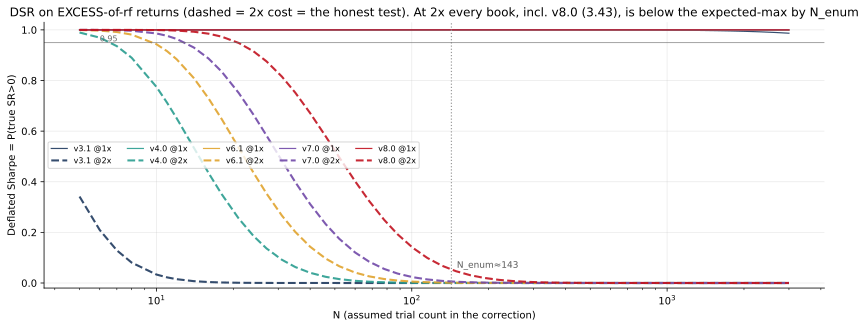

In [15]:
fig,ax=plt.subplots(figsize=(14,4.8))
sty={'v3.1':NAVY,'v4.0':TEAL,'v6.1':AMBER,'v7.0':PURPLE,'v8.0':RED}
for v in VERS:
    for mm,Vx,ls,lw in ((1,V1x,'-',1.2),(2,V2x,'--',2.1)):
        y=[dsr(RX[(v,mm)],Vx,N)[0] for N in Ngrid]
        ax.plot(Ngrid,y,color=sty[v],ls=ls,lw=lw,alpha=0.9,label=f'{v} @{mm}x')
ax.axvline(N_ENUM,color=GREY,lw=1.2,ls=':'); ax.text(N_ENUM*1.05,0.06,f'N_enum≈{N_ENUM}',color='0.35',fontsize=9)
ax.axhline(0.95,color='0.4',lw=1,ls='-',alpha=0.6); ax.text(6,0.955,'0.95',color='0.4',fontsize=8)
ax.set_xscale('log'); ax.set_xlabel('N (assumed trial count in the correction)')
ax.set_ylabel('Deflated Sharpe = P(true SR>0)'); ax.set_ylim(-0.02,1.03); ax.legend(ncol=5,loc='center left',fontsize=8)
ax.set_title('DSR on EXCESS-of-rf returns (dashed = 2x cost = the honest test). At 2x every book, incl. v8.0 (3.43), is below the expected-max by N_enum')
plt.show()

**Excess DSR read.**
- **1× cost, all books DSR ≈ 1.000 to N=1000.** Subtracting rf drops the 1× excess Sharpes to
  ~4.1–5.0 ann, but it *also* shrinks the 1× grid dispersion (sd 0.068 → 0.050), so the 1× expected-max
  benchmark is only ~2.5 ann at N≈143 (~3.1 at N=1000). Every book clears it with real margin — this is
  a genuine pass, not the "towering-by-construction" 1× we flagged on the raw basis. **v8.0's quoted
  1× excess Sharpe of 4.99 is deflation-robust.**
- **2× cost is where it breaks — and harder than on the raw basis.** The rf haircut roughly halves the
  2× excess Sharpes (v8.0 5.73 → **3.43**, v6.1 5.18 → 2.91, v3.1 3.62 → 1.62) while the 2× grid
  dispersion barely moves (sd 0.084 → 0.078), so the 2× excess expected-max stays high: **≈ 3.98 ann at
  N≈143**. Every book's 2×-excess Sharpe sits *below* that benchmark: DSR at N≈143 is v3.1 0.00, v4.0
  0.00, v6.1 0.001, v7.0 0.006, **v8.0 0.053** — the best of the ladder but nowhere near a 0.95 bar.
  v8.0 clears only at small N (0.52 at N=50, 0.999 at N=10).
- **So v8.0's quoted 3.43 (2×) is NOT multiple-testing-robust at the enumerated N.** It is roughly what
  the luckiest of ~140 correlated trials would post at 2× cost. The honest reading is not "v8.0 fails"
  but "at a 2× cost-stress the *excess* edge is inside the search noise; only the 1× (base-cost) excess
  Sharpe of 4.99 is separately defensible.

### 5b. Excess-basis PBO (CSCV, S=16)

Re-run the CSCV over-fit test on the **excess** grid matrices (`NET1x`, `NET2x`), same 16 blocks /
12,870 splits. PBO here answers a different question from DSR — is the *selection of the config* overfit
once configs are scored on excess returns? We also check whether the in-sample-best config changes when
the objective moves from raw to excess.

In [16]:
C1x=cscv(NET1x,16); C2x=cscv(NET2x,16)
for tag,C in [('1x',C1x),('2x',C2x)]:
    print(f'PBO@{tag} (excess) = {C["pbo"]:.4f} | median logit {np.median(C["logit"]):.2f} | IS-best mean OOS rank {C["rank"].mean():.3f} '
          f'| mean IS SR {C["is_sr"].mean():.3f} -> OOS SR {C["oos_sr"].mean():.3f} (degrade {1-C["oos_sr"].mean()/C["is_sr"].mean():.0%})')
print(f'\nfull-sample IS-best config @1x: raw    {SRg1.idxmax()}')
print(f'                                excess {SRx1.idxmax()}  (unchanged: {SRg1.idxmax()==SRx1.idxmax()})')
print(f'full-sample IS-best config @2x: raw    {SRg2.idxmax()}')
print(f'                                excess {SRx2.idxmax()}  (unchanged: {SRg2.idxmax()==SRx2.idxmax()})')

PBO@1x (excess) = 0.0342 | median logit 2.29 | IS-best mean OOS rank 0.859 | mean IS SR 0.271 -> OOS SR 0.229 (degrade 16%)
PBO@2x (excess) = 0.0306 | median logit 2.31 | IS-best mean OOS rank 0.871 | mean IS SR 0.188 -> OOS SR 0.136 (degrade 28%)

full-sample IS-best config @1x: raw    hl10|ti0.12|tk0.0|cap0.005|inv_vol|b0.5
                                excess hl10|ti0.12|tk0.0|cap0.005|inv_vol|b0.5  (unchanged: True)
full-sample IS-best config @2x: raw    hl14|ti0.12|tk0.0|cap0.01|inv_vol|b0.5
                                excess hl14|ti0.12|tk0.0|cap0.01|inv_vol|b0.5  (unchanged: True)


In [17]:
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,4.4))
for tag,C,c in [('1x',C1x,NAVY),('2x',C2x,AMBER)]:
    a1.hist(C['logit'],bins=40,color=c,alpha=0.5,density=True,label=f'{tag} cost (PBO={C["pbo"]:.3f})')
a1.axvline(0,color=RED,lw=1.5,ls='--'); a1.set_xlabel('logit of OOS rank of the IS-best config (excess)')
a1.set_ylabel('density'); a1.legend(); a1.set_title('(excess) CSCV logits — mass right of 0 = IS-best stays good OOS')
for tag,C,c in [('1x',C1x,NAVY),('2x',C2x,AMBER)]:
    a2.scatter(C['is_sr']*np.sqrt(365),C['oos_sr']*np.sqrt(365),s=6,color=c,alpha=0.25,label=f'{tag} cost')
lim=[min(C1x['oos_sr'].min(),C2x['oos_sr'].min())*np.sqrt(365)-0.5, max(C1x['is_sr'].max(),C2x['is_sr'].max())*np.sqrt(365)+0.5]
a2.plot(lim,lim,color=GREY,ls='--',lw=1,label='y=x (no degradation)')
a2.set_xlabel('IS excess annualized Sharpe of IS-best'); a2.set_ylabel('its OOS excess annualized Sharpe')
a2.legend(); a2.set_title('(excess) IS-best generalizes: points below y=x = honest OOS haircut')
plt.tight_layout(); plt.show()

**Excess PBO read.** PBO = **0.034 (1×) / 0.031 (2×)** on the excess grid — both far below 0.5,
and the IS-best config is **unchanged** from the raw grid at *both* cost levels (`hl10|ti0.12|…|b0.5`
@1×, `hl14|ti0.12|…|b0.5` @2×). Subtracting an rf common to every config barely reorders the ranking,
so the *selection procedure* is no more overfit on the excess basis than on the raw one: IS-best lands
at the ~86th OOS percentile, degrading only 16% (1×) / 28% (2×) IS→OOS. **This is the key disentangling
result:** the excess-basis 2× failure in §5a is **not** a selection-overfit problem (PBO says the
config ranking is stable) — it is a *level* problem. The honest 2×-excess Sharpe is simply low relative
to what the search's own dispersion would throw up by chance.

### 5c. Verdict on the excess basis — is v8.0's 4.99 / 3.43 deflation-robust?

- **4.99 (1×) — YES.** DSR = 1.000 at every N to 1000, clearing a real ~2.5-ann expected-max with
  margin. This is the number to quote as the multiple-testing-robust headline, with the standard label
  that 1× is the *modeled base-case* cost.
- **3.43 (2×) — NO, at the enumerated N.** DSR = 0.05 at N≈143 (the 2×-excess Sharpe sits *below* the
  ≈3.98-ann expected-max). It clears only if the effective search was ≤ ~50 trials. Quote 3.43 strictly
  as a **cost-stress** figure and state that under that stress the excess edge is inside the noise of
  the ~140-config search. Same lesson as the raw pass — 2× is where multiple testing bites — but
  sharper, because the rf haircut pushes even the best book's honest 2×-excess Sharpe under the bar.
- **v8.0 is still the right version to quote.** It has the highest excess Sharpe at both costs (4.99 /
  3.43 vs v7.0's 4.66 / 3.11 and v6.1's 4.45 / 2.91) precisely because the idle-cash credit removes the
  2022 opportunity-cost drag; on the excess basis the credit is a genuine, if small, improvement — not
  an accounting sleight-of-hand (crediting rf then quoting raw Sharpe would be; crediting rf and quoting
  excess is honest).

**Regime caveat — why the excess Sharpe is fragile.** rf went 0 (2021) → 5% (2023–24), so the excess
haircut is *front-loaded away* from where the returns are. Excess return by year (v8.0): **2021 +31.5%,
2022 −0.5%, 2023 +1.7%, 2024 +8.6%, 2025 −0.2%, 2026 +2.0%.** The whole-sample excess edge is carried by
2021 (rich carry, ~0 rf) and 2024; in the high-rate second half a market-neutral book returning ~1–2%
gross *loses* to 5% cash. DSR's track length T = 1,947 days treats every day as equally informative, but
the excess edge is concentrated in ~1.5 of the 5.4 years — a regime / small-sample risk the DSR estimate
does not price, and one that argues for treating even the 4.99 with humility. The whole 2022 flat window
earns rf on cash, so v8.0's credit is exactly what keeps 2022's excess from going as negative as v7.0's
(−0.5% vs −2.1%).

## 6. Honest conclusion — raw basis (original record)

*Written before the excess-of-rf headline; the current verdict is §5. The figures below are **raw
(vs-zero)** Sharpes and are retained as the historical record.*

- **The ladder mostly survives, but the number you quote must change.** Drop the 1× headline Sharpe
  (6.32 / 6.63): its DSR is 1.0 only because the in-sample gross edge is enormous, and DSR is blind
  to the cost/capacity that make a 6-Sharpe daily book unrealistic. Quote the **2×-cost** figures.
- **v3.1's realistic-cost edge does not clear a multiple-testing bar.** At 2× cost its Sharpe (3.62)
  gives DSR ≈ 0.05 at the enumerated N≈143 (≈0.02 by N=200). The *specific v3.1 point-configuration*
  is, at realistic cost, about what the luckiest of ~100 correlated trials would produce — so soften
  any claim that v3.1's exact knobs are special. The **family** (funding-carry + basis veto +
  inverse-vol sizing) is real; the last-decimal knob choice is not separately defensible.
- **v4.0 earns its keep on this test.** By cutting turnover its 2×-cost Sharpe rises to 4.85, giving
  DSR ≈ 0.95 at N≈143 and holding to N≈200 — a genuine multiple-testing margin v3.1 lacks (though it
  fails by N=1000, and its drawdown benefit still rests on ~one 2022 episode — a small-sample risk
  DSR/PBO cannot price).
- **The selection *process* is not mined:** PBO 0.10 (1×) / 0.002 (2×), IS→OOS degradation ~15-19%,
  IS-best at the ~82nd OOS percentile. Structural mitigants DSR/PBO don't capture — per-version
  temporal + cross-sectional OOS checks, three *rejected* nulls (G/H/per-asset), and mechanism-first
  (not performance-mined) vetoes — reinforce this, but do not rescue the v3.1 2×-cost point estimate.

**Bottom line:** report v6.1 at ~5.2 (or v4.0 at ~4.9) ann Sharpe (2× cost) as the defensible,
multiple-testing-robust figure; treat v3.1's 3.6 as inside the noise of the search and the 6.3 as
gross-only; and keep
watching the drawdown-episode count, capacity/slippage, and the engineered positive skew — those,
not multiple testing of these trials, are where this strategy is most likely to disappoint.